# Notebook for performing the Kruskall-Wallis analysis 

In [13]:
import pandas as pd
from scipy.stats import kruskal

In [ ]:
df = pd.read_csv("csv_data_for_analysis/fusion_100_no_tangles_3image.csv")

#
METRICS = "global_pixel_f1"

metric_cols = [f"image1_{METRICS}", "image2_global_pixel_f1", "image3_global_pixel_f1"]

groups = [row[metric_cols].values for _, row in df.iterrows()]
genotype_labels = df["genotype"].tolist()

stat, p_value = kruskal(*groups)

print(f"Kruskal-Wallis H-statistic: {stat:.4f}")
print(f"p-value: {p_value:.6f}")

if p_value < 0.05:
    print("Significant difference in instance F1 across genotypes (p < 0.05)")
else:
    print("No significant difference in instance F1 detected across genotypes")

Kruskal-Wallis H-statistic: 35.5374
p-value: 0.005284
Significant difference in instance F1 across genotypes (p < 0.05)


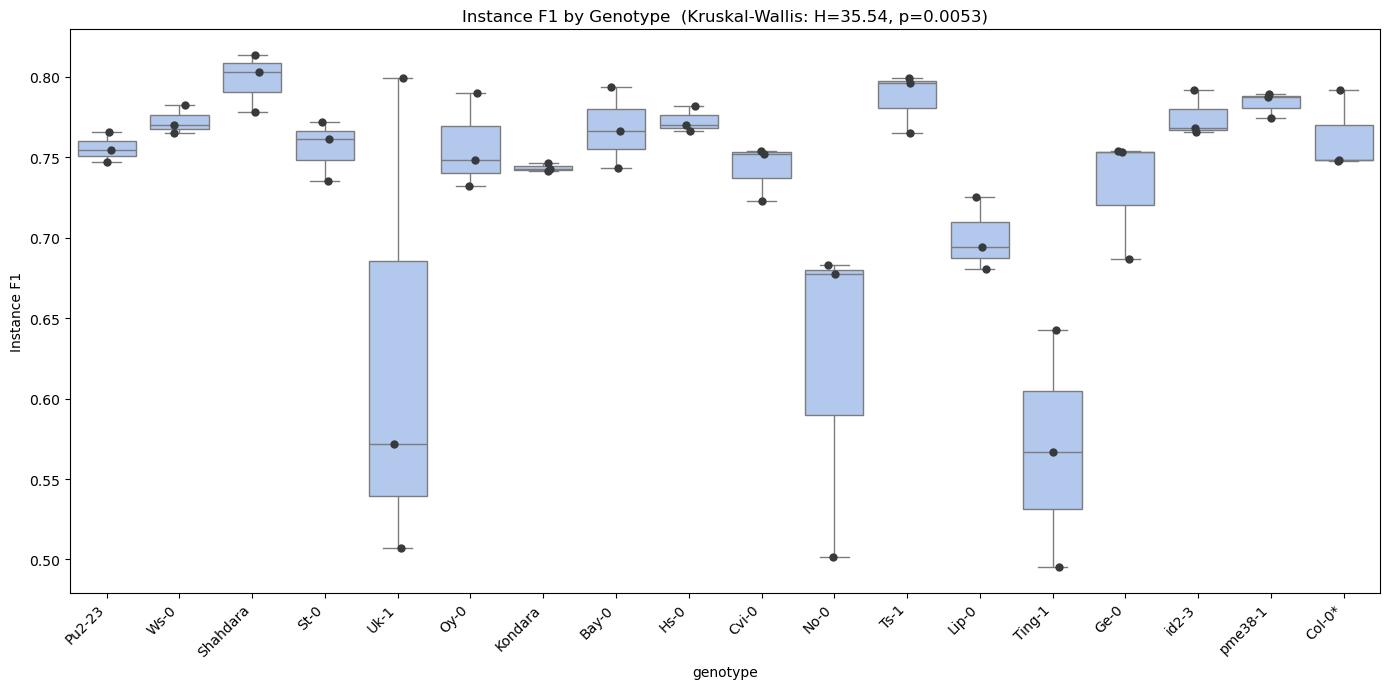

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# reshape to long format for seaborn (one row per genotype-image observation)
long_df = df.melt(
    id_vars="genotype",
    value_vars=metric_cols,
    var_name="image",
    value_name="instance_f1"
)

plt.figure(figsize=(14, 7))
sns.boxplot(data=long_df, x="genotype", y="instance_f1", color="#A9C6F5")
sns.stripplot(data=long_df, x="genotype", y="instance_f1", color="#373b3e", size=6, jitter=True)

plt.xticks(rotation=45, ha="right")
plt.ylabel("")
plt.title(f"Instance F1 by Genotype  (Kruskal-Wallis: H={stat:.2f}, p={p_value:.4f})")
plt.tight_layout()
plt.show()

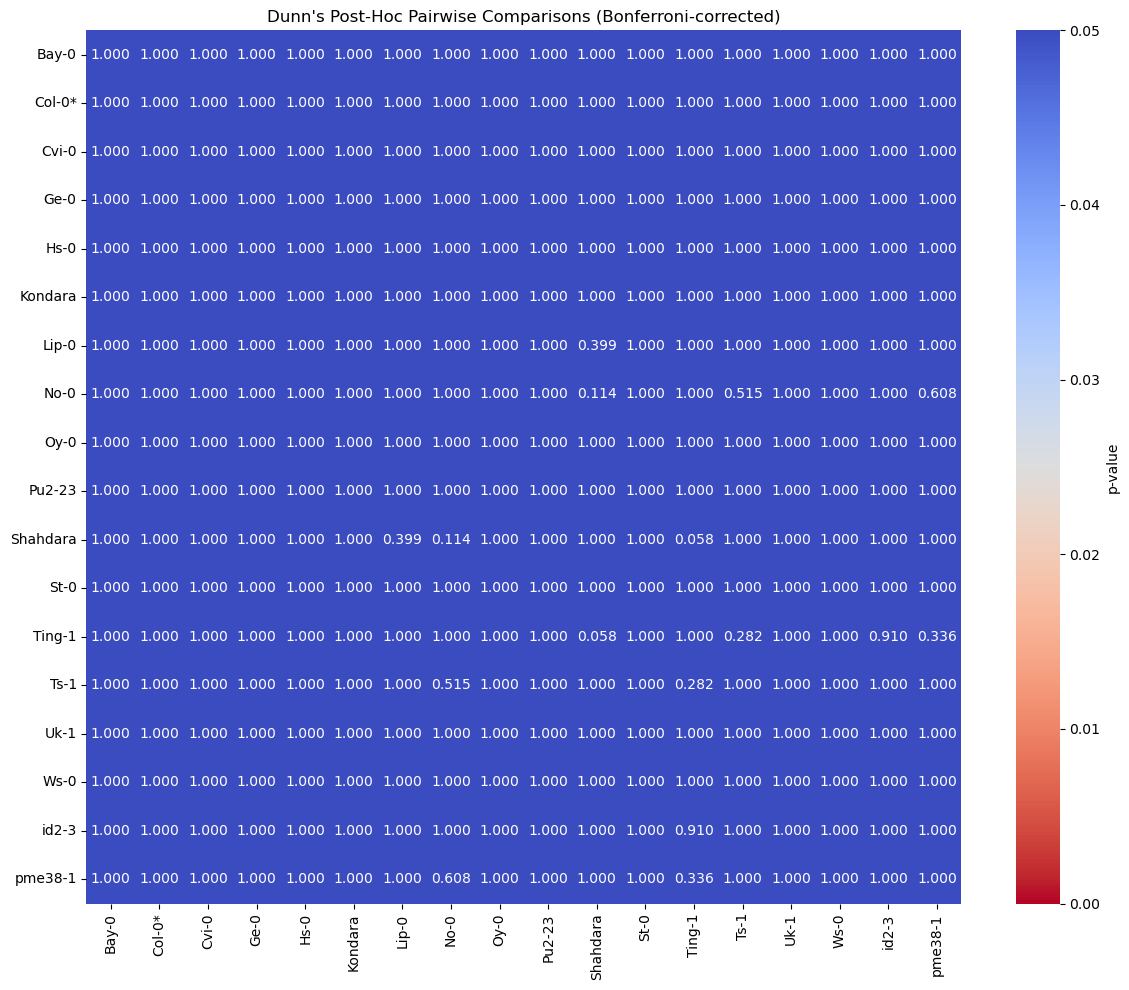

In [16]:
import scikit_posthocs as sp
import seaborn as sns

dunn_results = sp.posthoc_dunn(long_df, val_col="instance_f1", group_col="genotype", p_adjust="bonferroni")

plt.figure(figsize=(12, 10))
sns.heatmap(dunn_results, annot=True, fmt=".3f", cmap="coolwarm_r", vmin=0, vmax=0.05, cbar_kws={"label": "p-value"})
plt.title("Dunn's Post-Hoc Pairwise Comparisons (Bonferroni-corrected)")
plt.tight_layout()
plt.show()